<a href="https://colab.research.google.com/github/DanKatHav/thermal-surrogate-uncertainty/blob/main/NoisySineCurve.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import torch
print(torch.__version__)

2.11.0+cpu


0 1.0055063962936401
100 0.015299766324460506
200 0.008896024897694588
300 0.00884519424289465
400 0.008831048384308815


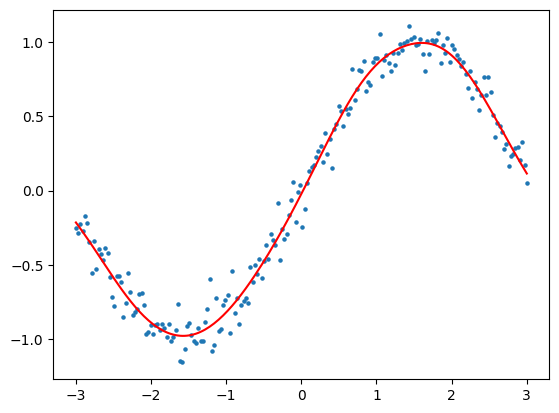

In [5]:
import torch, torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)                    #reproducible results

# 1) Date: a noisy sine curve
x= torch.linspace(-3,3,200).unsqueeze(1)
y= torch.sin(x) + 0.1* torch.randn_like(x)

# 2) Model: two hidden layers
model = nn.Sequential(
    nn.Linear(1,32), nn.Tanh(),
    nn.Linear(32,32), nn.Tanh(),
    nn.Linear(32,1),
)

# 3) Loss and optimiser
loss_fn = nn.MSELoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-2)

# 4) training loop
for epoch in range(500):
  opt.zero_grad()                     #reset gradients
  loss = loss_fn(model(x),y)          #compare prediction and data
  loss.backward()                     #compute gradients
  opt.step()                          #update the weights
  if epoch % 100 == 0:
    print(epoch, loss.item())

# 5) plot
plt.scatter(x,y, s=5)
plt.plot(x, model(x).detach(), "r")
plt.show()